# Trabajo académico final: análisis de datos industriales con Google Colab, Pandas y SQLite

**Asignatura:** Herramientas para Inteligencia Artificial  
**Programa:** Maestría en Inteligencia Artificial Aplicada – UTPL  
**Integrantes:** [Completar con los nombres de los integrantes]  
**Modalidad de desarrollo:** Google Colab y repositorio GitHub

## Presentación

Este cuaderno documenta el procesamiento y análisis de información relacionada con las condiciones de operación de maquinaria industrial. Se emplea el conjunto de datos **AI4I 2020 Predictive Maintenance Dataset**, disponible públicamente en el UCI Machine Learning Repository, para demostrar cómo trabajar con información almacenada inicialmente en un archivo CSV y posteriormente en una base de datos relacional SQLite.

El trabajo se desarrolla con herramientas de software libre y se ejecuta en Google Colab. Mediante **Pandas** se realizan consultas y resúmenes de datos, mientras que **Matplotlib** permite representar gráficamente variables operativas y registros de fallas. Los archivos generados se preparan para su publicación en GitHub, donde se complementará el trabajo con una Wiki académica.

> **Alcance:** esta actividad se concentra en la carga, organización, consulta, análisis y visualización de información. No incluye entrenamiento de modelos predictivos, ya que ese procedimiento no forma parte de los requisitos específicos de este trabajo.

## 1. Objetivos y organización del trabajo

**Objetivo general.** Integrar datos provenientes de un archivo CSV y una base de datos SQLite en un flujo de consulta y visualización desarrollado en Google Colab, utilizando Pandas, SQL y Matplotlib.

**Objetivos específicos**

1. Obtener un conjunto de datos de libre acceso en formato CSV.
2. Organizar la información en dos tablas relacionadas de una base de datos SQLite.
3. Consultar los datos almacenados mediante SQL y procesarlos con Pandas.
4. Elaborar visualizaciones que faciliten la interpretación de las condiciones operativas y de los registros de falla.
5. Preparar los archivos de datos, consultas y resultados para su publicación en un repositorio GitHub.

### Flujo de trabajo

**Descarga del CSV → Construcción de SQLite → Exportación SQL → Consultas con Pandas → Visualizaciones con Matplotlib → Preparación de entregables.**

Se conserva la misma fuente de datos en las dos representaciones (CSV y SQLite). Por tanto, **no se trata de dos muestras independientes**, sino de dos formas de almacenamiento y consulta que permiten demostrar las técnicas solicitadas.

## 2. Obtención del conjunto de datos desde un repositorio público

### 2.1. Fuente y descripción

Se utiliza el **AI4I 2020 Predictive Maintenance Dataset**, disponible en el [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/601/ai4i+2020+predictive+maintenance+dataset). Es un conjunto de datos sintético elaborado con fines de investigación y formación, orientado al análisis de condiciones operativas y fallas en equipos industriales.

El archivo tiene **10 000 registros y 14 columnas**. Entre sus variables se encuentran la temperatura del aire y del proceso, la velocidad de rotación, el torque y el desgaste de herramienta. También contiene una variable binaria, `Machine failure`, que identifica los registros con falla (`1`) y sin falla (`0`).

### 2.2. Procedimiento

La celda siguiente descarga el archivo comprimido desde la fuente pública, extrae el CSV y lo carga en un `DataFrame` de Pandas. Después genera una copia local denominada `ai4i2020.csv` y muestra las dimensiones, los nombres de las columnas y cinco registros iniciales.

Esta descarga directa permite que el notebook pueda ejecutarse desde otra computadora sin trasladar manualmente el dataset.

In [1]:

import pandas as pd
import requests
import zipfile
import io

# Descargar dataset original desde UCI
url = "https://archive.ics.uci.edu/static/public/601/ai4i+2020+predictive+maintenance+dataset.zip"

respuesta = requests.get(url, timeout=60)
respuesta.raise_for_status()

# Extraer el archivo CSV
with zipfile.ZipFile(io.BytesIO(respuesta.content)) as archivo_zip:
    with archivo_zip.open("ai4i2020.csv") as archivo:
        df = pd.read_csv(archivo)

# Guardar una copia en el entorno de Colab
df.to_csv("ai4i2020.csv", index=False)

# Verificar los datos
print("DIMENSIONES:", df.shape)
print("\nCOLUMNAS:")
print(df.columns.tolist())

print("\nPRIMEROS 5 REGISTROS:")
display(df.head())


DIMENSIONES: (10000, 14)

COLUMNAS:
['UDI', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']

PRIMEROS 5 REGISTROS:


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


**Resultado de la carga.** La salida confirma **10 000 filas y 14 columnas**. La tabla de los cinco primeros registros permite verificar que los campos se recuperaron con sus nombres originales.

**Interpretación:** en esta etapa todavía no se transforma la información; únicamente se obtiene y comprueba la estructura del archivo CSV. Esta verificación será la referencia para contrastar posteriormente la información almacenada en SQLite.

## 3. Construcción de la base de datos relacional SQLite

### 3.1. Justificación de la estructura

Para demostrar el manejo de una base de datos, la información del CSV se distribuye en **dos entidades relacionadas**:

| Tabla | Contenido | Identificador |
|---|---|---|
| `maquinas` | Identificador del registro, código del producto y tipo de producto | `UDI` (clave primaria) |
| `operaciones` | Temperaturas, velocidad, torque, desgaste y variables de falla | `UDI` (clave primaria y foránea) |

La columna `UDI` permite relacionar los datos de identificación con los parámetros operativos mediante una correspondencia uno a uno.

### 3.2. Procedimiento de creación

Se utiliza `sqlite3` para crear `mantenimiento_industrial.db`, definir las tablas y habilitar la comprobación de claves foráneas. Posteriormente, con `DataFrame.to_sql()` se insertan los registros procedentes del archivo original.

Finalmente, se verifica la cantidad de filas de cada tabla y se realiza un `INNER JOIN`, que recupera información conjunta de ambas entidades. Esta consulta muestra que la relación entre tablas funciona correctamente.

In [2]:

import sqlite3
import pandas as pd

# ==========================================
# 1. CREAR BASE DE DATOS SQLITE
# ==========================================

conexion = sqlite3.connect("mantenimiento_industrial.db")

conexion.execute("PRAGMA foreign_keys = ON")

cursor = conexion.cursor()

# ==========================================
# 2. CREAR TABLAS
# ==========================================

cursor.executescript("""
DROP TABLE IF EXISTS operaciones;
DROP TABLE IF EXISTS maquinas;

CREATE TABLE maquinas (
    UDI INTEGER PRIMARY KEY,
    product_id TEXT NOT NULL,
    tipo TEXT NOT NULL
);

CREATE TABLE operaciones (
    UDI INTEGER PRIMARY KEY,
    temperatura_aire REAL,
    temperatura_proceso REAL,
    velocidad_rotacion INTEGER,
    torque REAL,
    desgaste_herramienta INTEGER,
    falla_maquina INTEGER,
    twf INTEGER,
    hdf INTEGER,
    pwf INTEGER,
    osf INTEGER,
    rnf INTEGER,
    FOREIGN KEY (UDI) REFERENCES maquinas(UDI)
);
""")

# ==========================================
# 3. PREPARAR DATOS
# ==========================================

maquinas = df[[
    "UDI",
    "Product ID",
    "Type"
]].copy()

maquinas.columns = [
    "UDI",
    "product_id",
    "tipo"
]

operaciones = df[[
    "UDI",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
    "Machine failure",
    "TWF",
    "HDF",
    "PWF",
    "OSF",
    "RNF"
]].copy()

operaciones.columns = [
    "UDI",
    "temperatura_aire",
    "temperatura_proceso",
    "velocidad_rotacion",
    "torque",
    "desgaste_herramienta",
    "falla_maquina",
    "twf",
    "hdf",
    "pwf",
    "osf",
    "rnf"
]

# ==========================================
# 4. INSERTAR REGISTROS
# ==========================================

maquinas.to_sql(
    "maquinas",
    conexion,
    if_exists="append",
    index=False
)

operaciones.to_sql(
    "operaciones",
    conexion,
    if_exists="append",
    index=False
)

conexion.commit()

# ==========================================
# 5. VERIFICAR BASE DE DATOS
# ==========================================

print("BASE DE DATOS CREADA CORRECTAMENTE")

for tabla in ["maquinas", "operaciones"]:
    cantidad = pd.read_sql_query(
        f"SELECT COUNT(*) AS total FROM {tabla}",
        conexion
    )

    print(f"{tabla}: {cantidad.iloc[0]['total']} registros")

print("\nCONSULTA DE LAS DOS TABLAS:")

consulta = """
SELECT
    m.UDI,
    m.product_id,
    m.tipo,
    o.temperatura_aire,
    o.temperatura_proceso,
    o.velocidad_rotacion,
    o.torque,
    o.desgaste_herramienta,
    o.falla_maquina
FROM maquinas AS m
INNER JOIN operaciones AS o
    ON m.UDI = o.UDI
LIMIT 5;
"""

resultado = pd.read_sql_query(consulta, conexion)

display(resultado)


BASE DE DATOS CREADA CORRECTAMENTE
maquinas: 10000 registros
operaciones: 10000 registros

CONSULTA DE LAS DOS TABLAS:


,UDI,product_id,tipo,temperatura_aire,temperatura_proceso,velocidad_rotacion,torque,desgaste_herramienta,falla_maquina
0,1,M14860,M,298.1,308.6,1551,42.8,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0


### 3.3. Comprobación de la base creada

La salida obtenida confirma que las tablas **`maquinas` y `operaciones` contienen 10 000 registros cada una**. La consulta con `INNER JOIN` devuelve los cinco primeros registros, combinando la identificación del producto y sus parámetros de funcionamiento.

**Interpretación:** se conserva la correspondencia de los registros del CSV mediante la clave `UDI`. La estructura permite mantener separados los atributos de identificación y los atributos operativos sin perder la posibilidad de consultarlos de forma integrada.

> **Nota de reproducibilidad:** al volver a ejecutar la celda, las tablas se eliminan y reconstruyen deliberadamente para evitar registros duplicados en la carga.

## 4. Exportación de la estructura y los registros a SQL

Con el fin de incluir un archivo SQL en el repositorio de GitHub, se realiza una exportación completa de la base utilizando `conexion.iterdump()`. Esta operación produce un archivo con las instrucciones necesarias para crear las tablas e insertar sus datos.

Se generan dos archivos complementarios:

- **`mantenimiento_industrial.sql`**: instrucciones SQL que permiten reconstruir la base y sus registros.
- **`mantenimiento_industrial.db`**: archivo de base de datos SQLite ya creado, que puede abrirse directamente mediante una conexión local.

Ambos archivos se descargan desde Google Colab como respaldo de la implementación.

In [3]:

# ==========================================
# EXPORTAR LA BASE DE DATOS A SQL
# ==========================================

import sqlite3
from google.colab import files

# Guardar la estructura y los registros en SQL
with open("mantenimiento_industrial.sql", "w", encoding="utf-8") as archivo:
    for instruccion in conexion.iterdump():
        archivo.write(instruccion + "\n")

print("ARCHIVO SQL GENERADO CORRECTAMENTE")

# Verificar el contenido
with open("mantenimiento_industrial.sql", "r", encoding="utf-8") as archivo:
    for i, linea in enumerate(archivo):
        if i >= 12:
            break
        print(linea.rstrip())

# Descargar los archivos para la entrega
files.download("mantenimiento_industrial.sql")
files.download("mantenimiento_industrial.db")


ARCHIVO SQL GENERADO CORRECTAMENTE
BEGIN TRANSACTION;
CREATE TABLE maquinas (
    UDI INTEGER PRIMARY KEY,
    product_id TEXT NOT NULL,
    tipo TEXT NOT NULL
);
INSERT INTO "maquinas" VALUES(1,'M14860','M');
INSERT INTO "maquinas" VALUES(2,'L47181','L');
INSERT INTO "maquinas" VALUES(3,'L47182','L');
INSERT INTO "maquinas" VALUES(4,'L47183','L');
INSERT INTO "maquinas" VALUES(5,'L47184','L');
INSERT INTO "maquinas" VALUES(6,'M14865','M');


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 5. Consulta y manipulación de la información con Pandas

### 5.1. Consulta integrada de las tablas

Se recupera la información de `maquinas` y `operaciones` mediante una consulta SQL con `INNER JOIN`. Para transformar los resultados en un `DataFrame`, se utiliza `pd.read_sql_query()`.

A partir de esta consulta se obtiene un conjunto integrado de **10 000 registros y 9 columnas**, útil para generar tablas descriptivas y visualizaciones.

### 5.2. Consultas de análisis

Se realizan dos operaciones adicionales:

1. **Distribución de fallas:** se usa `GROUP BY` en SQL para contabilizar los registros con y sin falla.
2. **Resumen por tipo de producto:** se agrupan los registros mediante `groupby()` y `agg()` de Pandas. Se calculan la cantidad de registros, la cantidad de fallas, el torque promedio, la velocidad promedio y el porcentaje de fallas por tipo.

Finalmente, el resultado de la consulta integrada se guarda en `dataset_final.csv`, que constituye el archivo de datos procesado para el repositorio.

In [4]:

import pandas as pd
import sqlite3

# ==========================================
# 1. CONECTAR CON SQLITE
# ==========================================

conexion = sqlite3.connect("mantenimiento_industrial.db")

# ==========================================
# 2. CONSULTAR LAS DOS TABLAS
# ==========================================

consulta = """
SELECT
    m.UDI,
    m.product_id,
    m.tipo,
    o.temperatura_aire,
    o.temperatura_proceso,
    o.velocidad_rotacion,
    o.torque,
    o.desgaste_herramienta,
    o.falla_maquina
FROM maquinas AS m
INNER JOIN operaciones AS o
    ON m.UDI = o.UDI
"""

datos_sql = pd.read_sql_query(consulta, conexion)

print("REGISTROS CONSULTADOS DESDE SQLITE:")
print(datos_sql.shape)

display(datos_sql.head())

# ==========================================
# 3. CONSULTAR DISTRIBUCION DE FALLAS
# ==========================================

consulta_fallas = """
SELECT
    falla_maquina,
    COUNT(*) AS cantidad
FROM operaciones
GROUP BY falla_maquina
ORDER BY falla_maquina
"""

fallas_sql = pd.read_sql_query(
    consulta_fallas,
    conexion
)

print("\nDISTRIBUCION DE FALLAS:")
display(fallas_sql)

# ==========================================
# 4. RESUMEN POR TIPO DE PRODUCTO
# ==========================================

resumen = datos_sql.groupby("tipo").agg(
    cantidad=("UDI", "count"),
    fallas=("falla_maquina", "sum"),
    torque_promedio=("torque", "mean"),
    velocidad_promedio=("velocidad_rotacion", "mean")
).reset_index()

resumen["porcentaje_fallas"] = (
    resumen["fallas"] / resumen["cantidad"] * 100
).round(2)

print("\nRESUMEN POR TIPO DE PRODUCTO:")
display(resumen)

# ==========================================
# 5. GENERAR DATASET FINAL
# ==========================================

datos_sql.to_csv("dataset_final.csv", index=False)

print("\nDATASET FINAL GENERADO")
print("Archivo: dataset_final.csv")
print("Dimensiones:", datos_sql.shape)


REGISTROS CONSULTADOS DESDE SQLITE:
(10000, 9)


,UDI,product_id,tipo,temperatura_aire,temperatura_proceso,velocidad_rotacion,torque,desgaste_herramienta,falla_maquina
0,1,M14860,M,298.1,308.6,1551,42.8,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0



DISTRIBUCION DE FALLAS:


,falla_maquina,cantidad
0,0,9661
1,1,339



RESUMEN POR TIPO DE PRODUCTO:


,tipo,cantidad,fallas,torque_promedio,velocidad_promedio,porcentaje_fallas
0,H,1003,21,39.838285,1538.147557,2.09
1,L,6000,235,39.996600,1539.469167,3.92
2,M,2997,83,40.017251,1537.598932,2.77



DATASET FINAL GENERADO
Archivo: dataset_final.csv
Dimensiones: (10000, 9)


### 5.3. Interpretación de los resultados de las consultas

La distribución de la variable objetivo presenta:

| Condición | Registros | Porcentaje del total |
|---|---:|---:|
| Sin falla (`0`) | 9 661 | 96,61 % |
| Con falla (`1`) | 339 | 3,39 % |
| **Total** | **10 000** | **100,00 %** |

Se observa un **desbalance entre ambas clases**, dado que los registros sin falla constituyen la gran mayoría del conjunto de datos.

El resumen por tipo de producto muestra los siguientes resultados:

| Tipo | Cantidad | Registros con falla | Porcentaje de fallas |
|---|---:|---:|---:|
| H | 1 003 | 21 | 2,09 % |
| L | 6 000 | 235 | 3,92 % |
| M | 2 997 | 83 | 2,77 % |

El tipo **L** reúne tanto la mayor cantidad de registros como el mayor porcentaje observado de fallas (3,92 %). Estos porcentajes describen la distribución del dataset y **no deben interpretarse como tasas de falla de equipos reales**.

El archivo `dataset_final.csv` conserva las **9 columnas seleccionadas** en la consulta integrada, distintas de las 14 columnas del CSV original.

## 6. Elaboración de visualizaciones con Matplotlib

La representación gráfica facilita la inspección de la distribución de los registros y de sus principales variables operativas. En esta actividad se generan cuatro visualizaciones, que se guardan automáticamente como imágenes PNG en la carpeta `visualizaciones/`.

| Figura | Visualización | Propósito |
|---|---|---|
| 1 | Distribución de fallas | Comparar las cantidades de registros con y sin falla |
| 2 | Porcentaje de fallas por tipo | Comparar la proporción de fallas entre tipos H, L y M |
| 3 | Histograma del torque | Describir la frecuencia de los valores de torque |
| 4 | Velocidad y torque según condición | Explorar la relación entre dos variables operativas distinguiendo los registros de falla |

La celda siguiente produce las cuatro figuras y conserva los archivos con una resolución de 200 dpi para su presentación en GitHub.

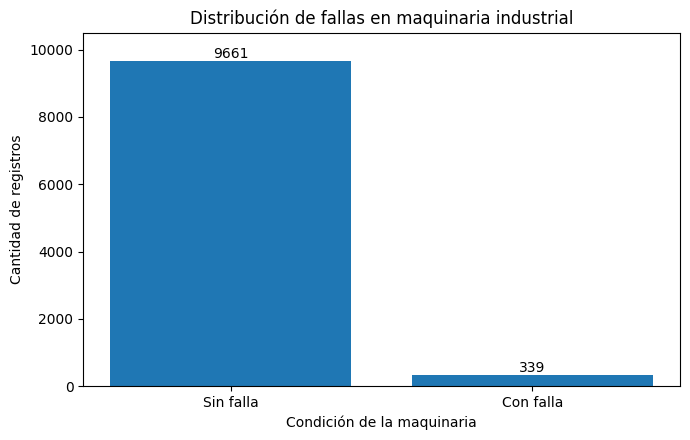

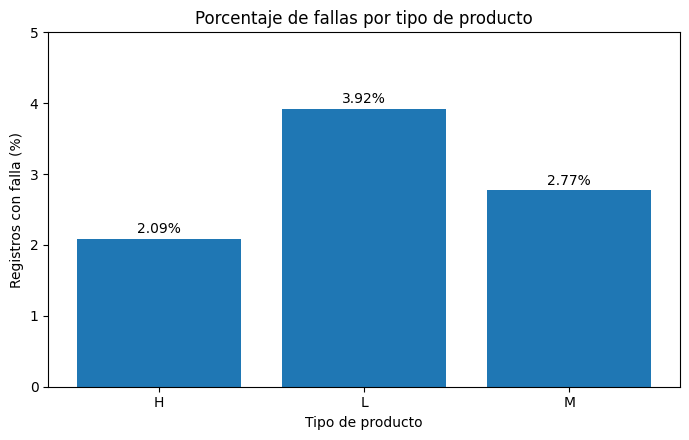

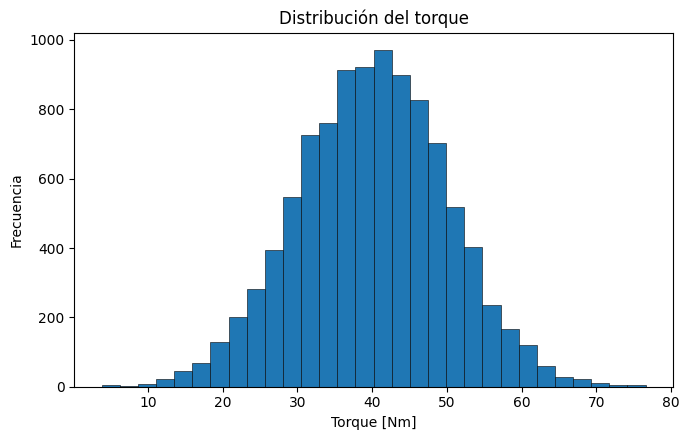

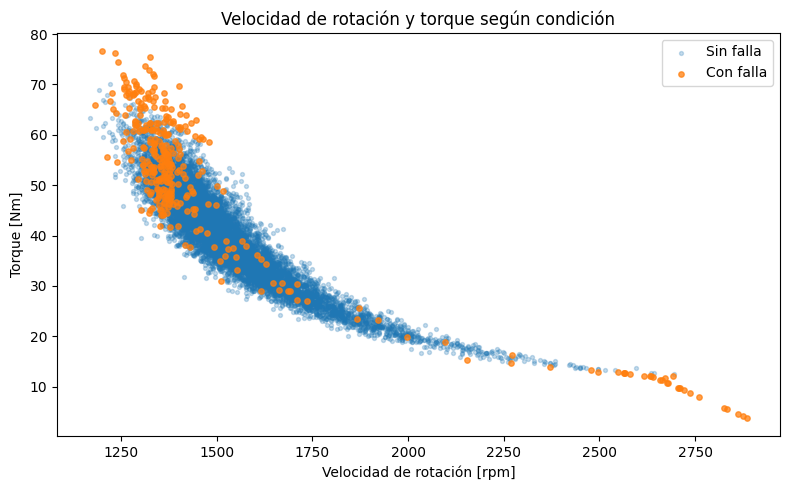

VISUALIZACIONES GENERADAS CORRECTAMENTE
Carpeta: visualizaciones
- 01_distribucion_fallas.png
- 02_fallas_por_tipo.png
- 03_distribucion_torque.png
- 04_velocidad_torque.png


In [5]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ==========================================
# 1. CREAR CARPETA DE VISUALIZACIONES
# ==========================================

carpeta = Path("visualizaciones")
carpeta.mkdir(exist_ok=True)

# ==========================================
# 2. DISTRIBUCION DE FALLAS
# ==========================================

conteo = datos_sql["falla_maquina"].value_counts().sort_index()

plt.figure(figsize=(7, 4.5))

plt.bar(
    ["Sin falla", "Con falla"],
    [conteo.get(0, 0), conteo.get(1, 0)]
)

plt.title("Distribución de fallas en maquinaria industrial")
plt.xlabel("Condición de la maquinaria")
plt.ylabel("Cantidad de registros")

for i, valor in enumerate([conteo.get(0, 0), conteo.get(1, 0)]):
    plt.text(i, valor + 80, str(valor), ha="center")

plt.ylim(0, 10500)
plt.tight_layout()
plt.savefig(carpeta / "01_distribucion_fallas.png", dpi=200)
plt.show()

# ==========================================
# 3. PORCENTAJE DE FALLAS POR TIPO
# ==========================================

plt.figure(figsize=(7, 4.5))

plt.bar(
    resumen["tipo"],
    resumen["porcentaje_fallas"]
)

plt.title("Porcentaje de fallas por tipo de producto")
plt.xlabel("Tipo de producto")
plt.ylabel("Registros con falla (%)")

for i, valor in enumerate(resumen["porcentaje_fallas"]):
    plt.text(i, valor + 0.08, f"{valor:.2f}%", ha="center")

plt.ylim(0, 5)
plt.tight_layout()
plt.savefig(carpeta / "02_fallas_por_tipo.png", dpi=200)
plt.show()

# ==========================================
# 4. DISTRIBUCION DEL TORQUE
# ==========================================

plt.figure(figsize=(7, 4.5))

plt.hist(
    datos_sql["torque"],
    bins=30,
    edgecolor="black",
    linewidth=0.4
)

plt.title("Distribución del torque")
plt.xlabel("Torque [Nm]")
plt.ylabel("Frecuencia")

plt.tight_layout()
plt.savefig(carpeta / "03_distribucion_torque.png", dpi=200)
plt.show()

# ==========================================
# 5. VELOCIDAD VS TORQUE
# ==========================================

plt.figure(figsize=(8, 5))

sin_falla = datos_sql[datos_sql["falla_maquina"] == 0]
con_falla = datos_sql[datos_sql["falla_maquina"] == 1]

plt.scatter(
    sin_falla["velocidad_rotacion"],
    sin_falla["torque"],
    s=8,
    alpha=0.25,
    label="Sin falla"
)

plt.scatter(
    con_falla["velocidad_rotacion"],
    con_falla["torque"],
    s=15,
    alpha=0.75,
    label="Con falla"
)

plt.title("Velocidad de rotación y torque según condición")
plt.xlabel("Velocidad de rotación [rpm]")
plt.ylabel("Torque [Nm]")
plt.legend()
plt.tight_layout()

plt.savefig(carpeta / "04_velocidad_torque.png", dpi=200)
plt.show()

print("VISUALIZACIONES GENERADAS CORRECTAMENTE")
print("Carpeta:", carpeta)

for archivo in sorted(carpeta.glob("*.png")):
    print("-", archivo.name)


### 6.1. Interpretación de las visualizaciones

**Figura 1. Distribución de fallas.** Se observa una diferencia marcada entre los **9 661 registros sin falla** y los **339 registros con falla**. Esta distribución confirma que la clase de falla aparece con mucha menor frecuencia dentro del dataset.

**Figura 2. Porcentaje de fallas por tipo de producto.** El tipo **L** presenta la mayor proporción de registros con falla (**3,92 %**), seguido por el tipo **M** (**2,77 %**) y el tipo **H** (**2,09 %**). La comparación utiliza porcentajes, por lo que considera el diferente tamaño de cada grupo.

**Figura 3. Distribución del torque.** El histograma concentra una parte importante de los registros alrededor de valores intermedios, aproximadamente entre **30 y 50 Nm**. Los valores más alejados de esa zona aparecen con menor frecuencia.

**Figura 4. Velocidad de rotación frente a torque.** El diagrama de dispersión permite visualizar una relación inversa general: conforme aumenta la velocidad de rotación, el torque tiende a ser menor. Los puntos correspondientes a registros con falla se distinguen de los registros sin falla, aunque existen zonas de superposición. El gráfico es **descriptivo** y no demuestra por sí solo causalidad.

En conjunto, estas visualizaciones permiten comunicar características relevantes del dataset sin necesidad de entrenar un modelo de aprendizaje automático.

## 7. Preparación de archivos para el repositorio GitHub

La actividad solicita publicar los insumos y resultados en un repositorio de GitHub. La siguiente celda prepara una carpeta comprimida con el CSV original, el dataset final, el archivo SQL, la base SQLite y las imágenes generadas.

**Archivos incluidos en el paquete:**

- `ai4i2020.csv`: archivo CSV de origen.
- `dataset_final.csv`: datos integrados obtenidos mediante la consulta SQL.
- `mantenimiento_industrial.sql`: estructura e instrucciones para reconstruir la base.
- `mantenimiento_industrial.db`: base de datos SQLite.
- `visualizaciones/`: cuatro imágenes de los gráficos realizados.

**Importante:** el notebook `.ipynb` se descarga por separado desde **Archivo → Descargar → Descargar archivo .ipynb** y también debe subirse a GitHub. La celda siguiente no lo incorpora automáticamente al archivo ZIP.

El script de creación de la base se encuentra documentado en la sección 3 del notebook. Si el docente solicita un script `.py` independiente, este código puede exportarse adicionalmente como archivo complementario.

In [6]:

from google.colab import files
from pathlib import Path
import shutil

# Crear carpeta de entrega
carpeta = Path("Trabajo_Final_IA")
carpeta.mkdir(exist_ok=True)

# Copiar datasets
shutil.copy("ai4i2020.csv", carpeta / "ai4i2020.csv")
shutil.copy("dataset_final.csv", carpeta / "dataset_final.csv")

# Copiar archivos de base de datos
shutil.copy(
    "mantenimiento_industrial.sql",
    carpeta / "mantenimiento_industrial.sql"
)

shutil.copy(
    "mantenimiento_industrial.db",
    carpeta / "mantenimiento_industrial.db"
)

# Copiar visualizaciones
shutil.copytree(
    "visualizaciones",
    carpeta / "visualizaciones",
    dirs_exist_ok=True
)

# Comprimir carpeta
archivo_zip = shutil.make_archive(
    "Trabajo_Final_IA",
    "zip",
    root_dir=".",
    base_dir="Trabajo_Final_IA"
)

print("ARCHIVOS PREPARADOS CORRECTAMENTE")

for archivo in sorted(carpeta.rglob("*")):
    if archivo.is_file():
        print(archivo)

files.download(archivo_zip)


ARCHIVOS PREPARADOS CORRECTAMENTE
Trabajo_Final_IA/ai4i2020.csv
Trabajo_Final_IA/dataset_final.csv
Trabajo_Final_IA/mantenimiento_industrial.db
Trabajo_Final_IA/mantenimiento_industrial.sql
Trabajo_Final_IA/visualizaciones/01_distribucion_fallas.png
Trabajo_Final_IA/visualizaciones/02_fallas_por_tipo.png
Trabajo_Final_IA/visualizaciones/03_distribucion_torque.png
Trabajo_Final_IA/visualizaciones/04_velocidad_torque.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 8. Conclusiones

1. Se obtuvo y procesó el dataset AI4I 2020 desde una fuente pública, comprobando su estructura de **10 000 registros y 14 columnas** en Google Colab.
2. Se construyó una base de datos SQLite con dos tablas relacionadas, `maquinas` y `operaciones`, cada una con 10 000 registros, y se exportó su contenido a un archivo SQL para facilitar la entrega y reproducción del trabajo.
3. Las consultas realizadas mediante SQL y Pandas permitieron integrar los datos, cuantificar los registros de falla y obtener indicadores agrupados por tipo de producto. El conjunto final resultó en **10 000 registros y 9 columnas**.
4. Se generaron cuatro visualizaciones con Matplotlib que describen la distribución de fallas, los porcentajes por tipo de producto, el comportamiento del torque y la relación entre torque y velocidad de rotación.
5. El desarrollo permitió integrar una plataforma colaborativa, herramientas de manipulación de datos, una base de datos y técnicas de visualización, cumpliendo el flujo práctico solicitado para el trabajo académico final.

## 9. Referencias y recursos utilizados

- UCI Machine Learning Repository. (2020). *AI4I 2020 Predictive Maintenance Dataset* [Conjunto de datos]. https://doi.org/10.24432/C5HS5C
- Google. (s. f.). *Colaboratory*. https://colab.research.google.com/
- pandas development team. (s. f.). *pandas documentation*. https://pandas.pydata.org/docs/
- Matplotlib Development Team. (s. f.). *Matplotlib documentation*. https://matplotlib.org/stable/
- Python Software Foundation. (s. f.). *sqlite3 — DB-API 2.0 interface for SQLite databases*. https://docs.python.org/3/library/sqlite3.html

---

**Nota para la entrega:** la consigna también solicita un informe en la **Wiki de GitHub**, con introducción, marco teórico, descripción del dataset, procedimiento, visualizaciones, conclusiones y bibliografía. Este notebook explica el desarrollo técnico, pero **no sustituye la publicación de la Wiki**.